## 0. Carga de paquetes

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", "{:.4f}".format)

## 1. Carga de datos

In [5]:
# --- 1. Carga de datos ---
df_train = pd.read_csv("../data/training_data.csv")
df_test = pd.read_csv("../data/blind_test_data.csv")

features = [c for c in df_train.columns if c != "target"]
print(f"Training:  {df_train.shape[0]} filas x {df_train.shape[1]} columnas")
print(f"Blind test: {df_test.shape[0]} filas x {df_test.shape[1]} columnas")

Training:  800 filas x 21 columnas
Blind test: 200 filas x 20 columnas


## 2. Inspección general

In [6]:
# Tipos de datos y valores nulos
print("=== Info del dataset de entrenamiento ===")
print(df_train.info())
print("\n=== Valores nulos por columna ===")
print(df_train.isnull().sum())
print(f"\nTotal de valores nulos: {df_train.isnull().sum().sum()}")

=== Info del dataset de entrenamiento ===
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 21 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   feature_0   800 non-null    float64
 1   feature_1   800 non-null    float64
 2   feature_2   800 non-null    float64
 3   feature_3   800 non-null    float64
 4   feature_4   800 non-null    float64
 5   feature_5   800 non-null    float64
 6   feature_6   800 non-null    float64
 7   feature_7   800 non-null    float64
 8   feature_8   800 non-null    float64
 9   feature_9   800 non-null    float64
 10  feature_10  800 non-null    float64
 11  feature_11  800 non-null    float64
 12  feature_12  800 non-null    float64
 13  feature_13  800 non-null    float64
 14  feature_14  800 non-null    float64
 15  feature_15  800 non-null    float64
 16  feature_16  800 non-null    float64
 17  feature_17  800 non-null    float64
 18  feature_18  800 non-null    float64
 19

In [7]:
# Estadísticas descriptivas
df_train.describe().T

,count,mean,std,min,25%,50%,75%,max
feature_0,800.0000,468.1816,270.7974,0.9166,239.3301,477.7506,704.6503,940.7715
feature_1,800.0000,301.9602,170.6911,0.8001,157.3382,303.2572,448.8782,595.3599
feature_2,800.0000,317.1330,176.5019,0.1730,167.5163,326.3102,474.4845,614.2716
feature_3,800.0000,283.2135,157.6982,0.3088,151.3028,294.5744,415.8062,549.8962
feature_4,800.0000,485.9759,272.5940,0.5985,250.3054,493.4705,720.7477,950.0174
feature_5,800.0000,320.9539,185.1572,0.9973,158.3746,328.7225,480.0766,638.1998
feature_6,800.0000,217.1363,123.6607,0.4024,106.8766,217.0981,327.4113,426.3083
feature_7,800.0000,387.1963,235.1314,0.4748,195.0379,364.1242,588.5650,809.3468
feature_8,800.0000,179.4855,104.0593,0.7278,94.2203,173.3648,268.7905,367.0848
feature_9,800.0000,196.0031,111.0427,0.2643,95.0524,199.5870,291.5466,384.9191


In [8]:
# Verificar duplicados
n_duplicados = df_train.duplicated().sum()
print(f"Filas duplicadas en training: {n_duplicados}")
n_duplicados_test = df_test.duplicated().sum()
print(f"Filas duplicadas en test: {n_duplicados_test}")

Filas duplicadas en training: 0
Filas duplicadas en test: 0


## 3. Distribución de la variable objetivo (target)

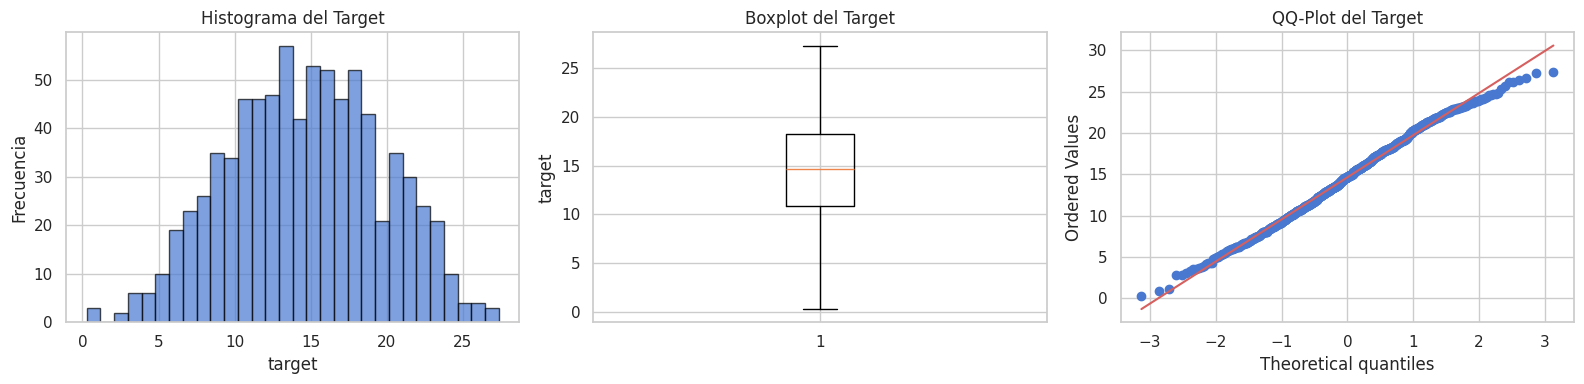

Shapiro-Wilk: statistic=0.9943, p-value=0.004147
Skewness: -0.0398
Kurtosis: -0.5402


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Histograma
axes[0].hist(df_train["target"], bins=30, edgecolor="black", alpha=0.7)
axes[0].set_title("Histograma del Target")
axes[0].set_xlabel("target")
axes[0].set_ylabel("Frecuencia")

# Boxplot
axes[1].boxplot(df_train["target"], vert=True)
axes[1].set_title("Boxplot del Target")
axes[1].set_ylabel("target")

# QQ-plot
stats.probplot(df_train["target"], dist="norm", plot=axes[2])
axes[2].set_title("QQ-Plot del Target")

plt.tight_layout()
plt.show()

# Test de normalidad
stat_sw, p_sw = stats.shapiro(df_train["target"])
print(f"Shapiro-Wilk: statistic={stat_sw:.4f}, p-value={p_sw:.6f}")
print(f"Skewness: {df_train['target'].skew():.4f}")
print(f"Kurtosis: {df_train['target'].kurtosis():.4f}")

## 4. Distribuciones de las features

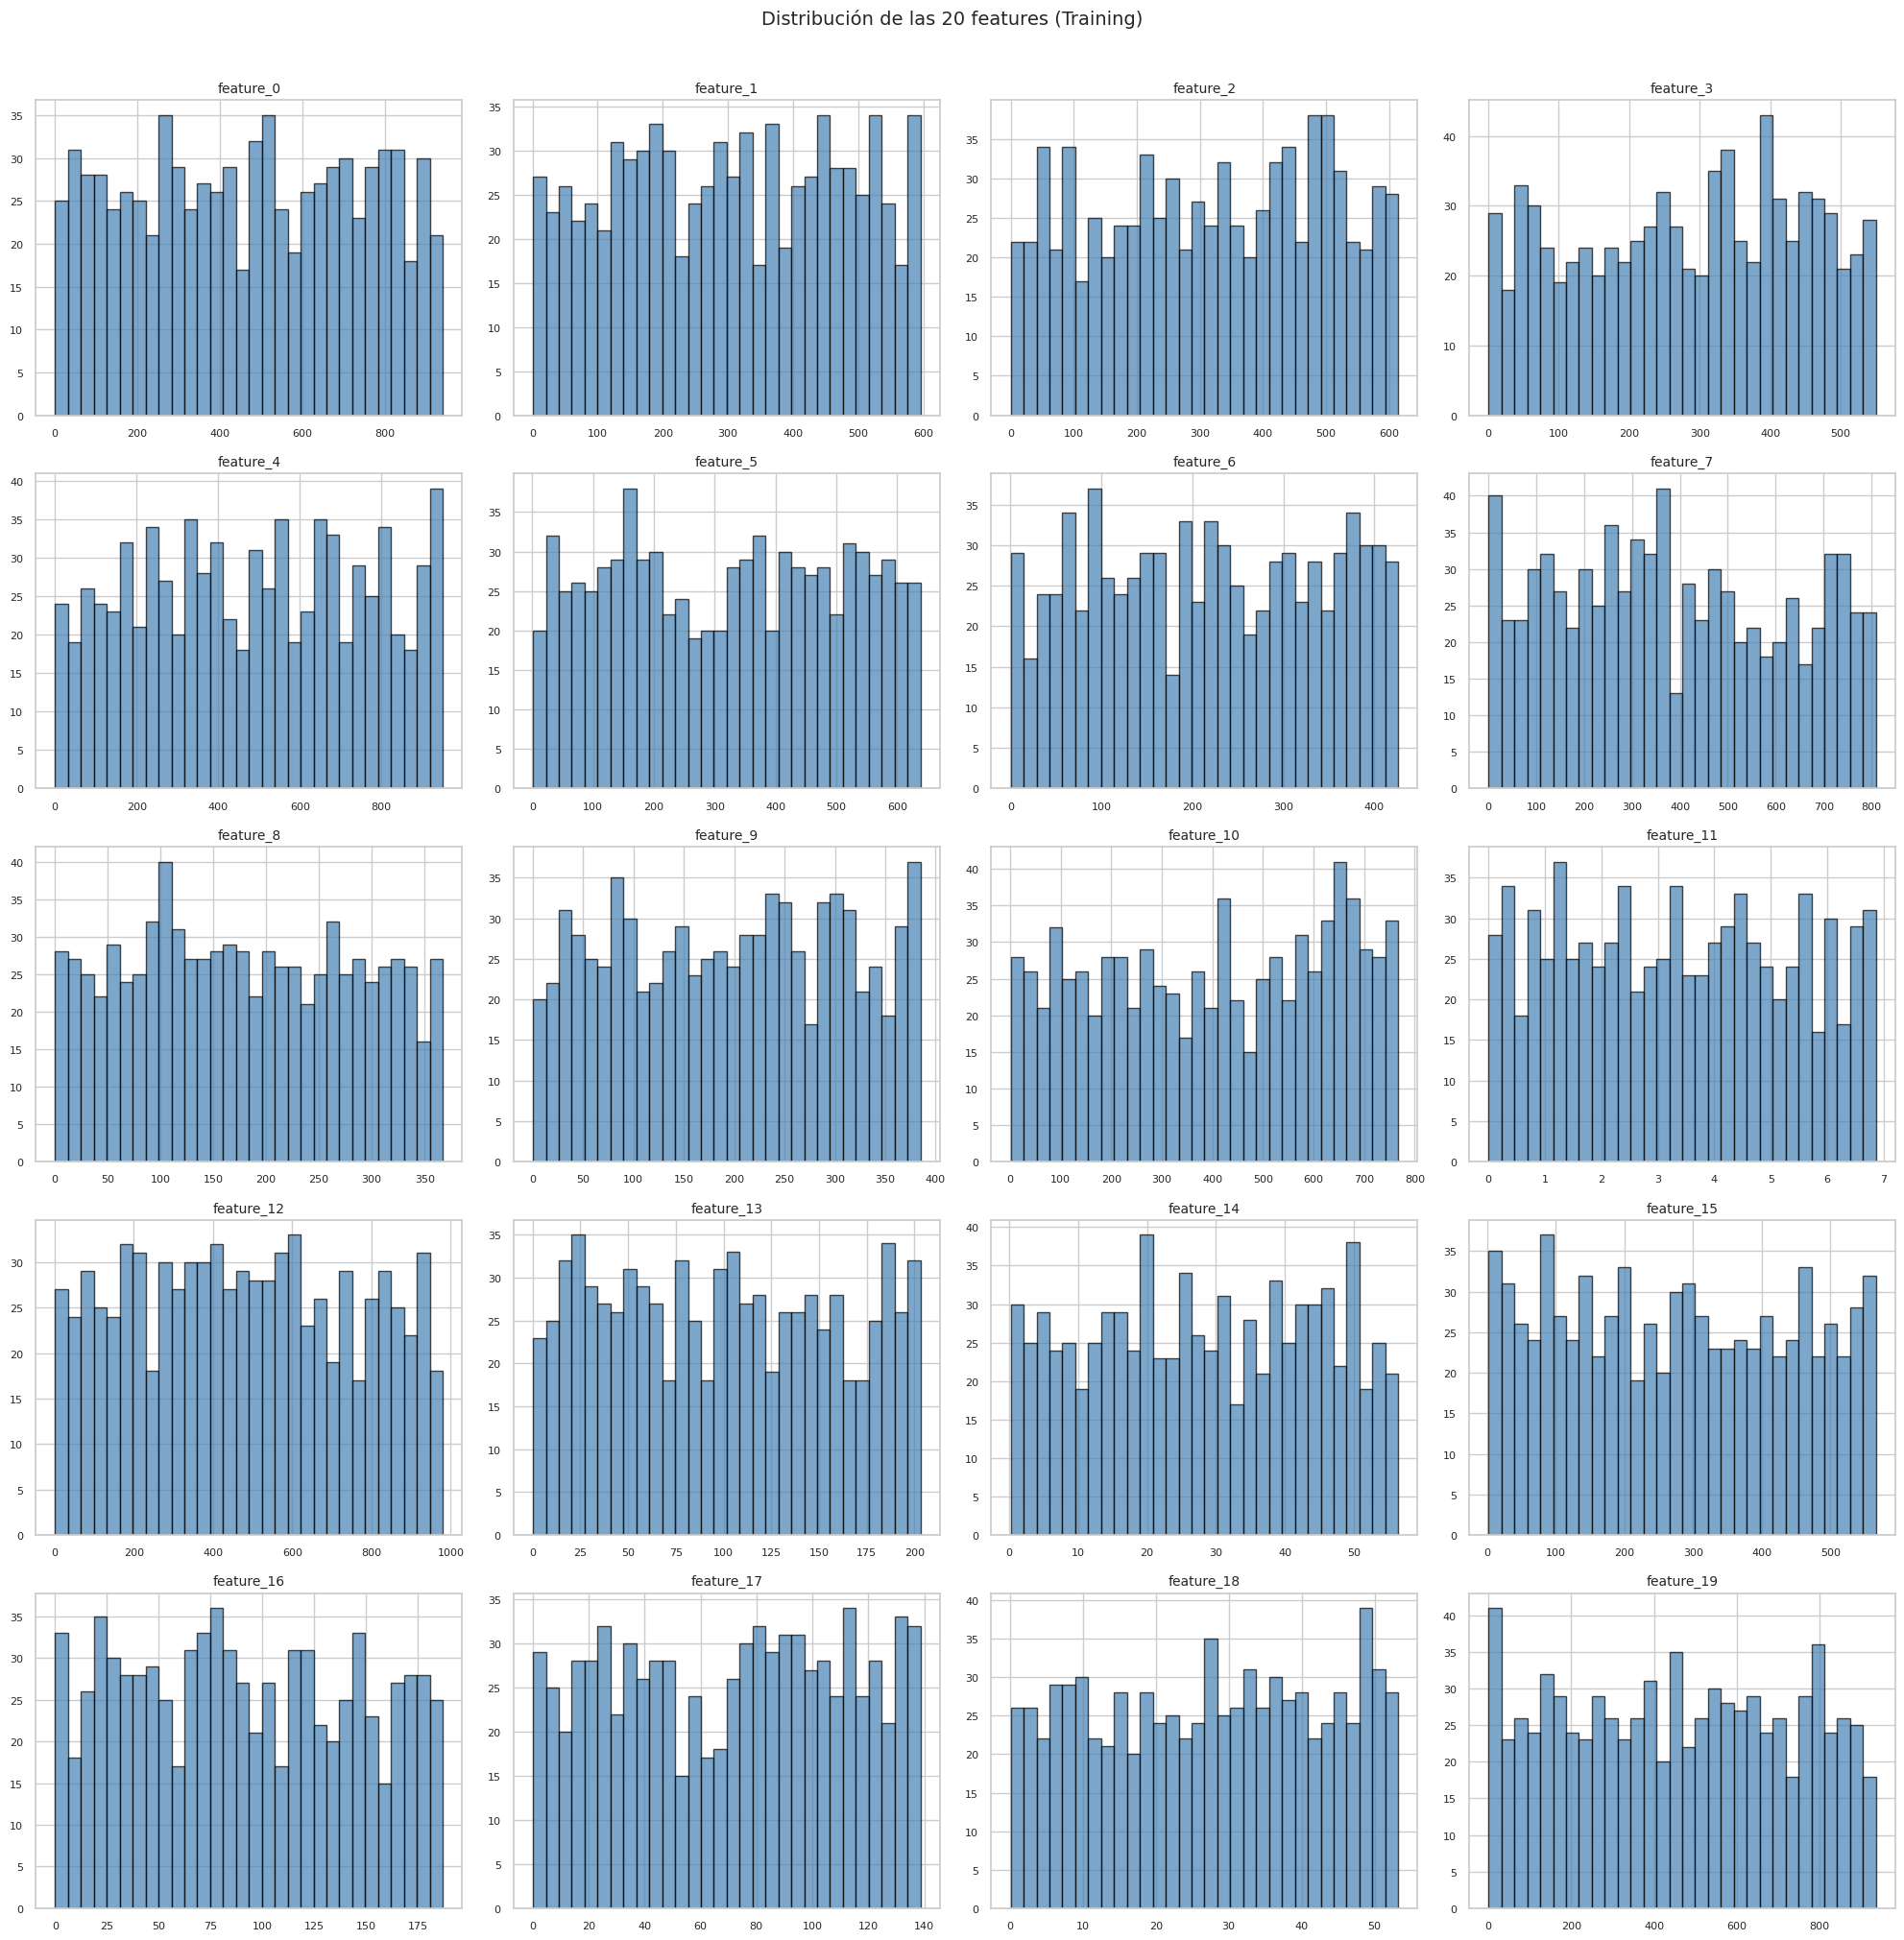

In [10]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].hist(df_train[feat], bins=30, edgecolor="black", alpha=0.7, color="steelblue")
    axes[i].set_title(feat, fontsize=10)
    axes[i].tick_params(labelsize=8)

plt.suptitle("Distribución de las 20 features (Training)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# Skewness y kurtosis de cada feature
skew_kurt = pd.DataFrame({
    "skewness": df_train[features].skew(),
    "kurtosis": df_train[features].kurtosis()
})
print("Features con alta asimetría (|skew| > 1):")
print(skew_kurt[skew_kurt["skewness"].abs() > 1])
print(f"\n{'='*50}")
print(skew_kurt.sort_values("skewness", ascending=False))

Features con alta asimetría (|skew| > 1):
Empty DataFrame
Columns: [skewness, kurtosis]
Index: []

            skewness  kurtosis
feature_7     0.1267   -1.1549
feature_16    0.0778   -1.1788
feature_13    0.0748   -1.2101
feature_8     0.0670   -1.1637
feature_15    0.0566   -1.2259
feature_12    0.0512   -1.1351
feature_11    0.0473   -1.1831
feature_5    -0.0008   -1.2536
feature_19   -0.0042   -1.2004
feature_0    -0.0069   -1.2097
feature_6    -0.0071   -1.2248
feature_4    -0.0078   -1.1690
feature_9    -0.0097   -1.1926
feature_1    -0.0207   -1.1887
feature_14   -0.0288   -1.1925
feature_18   -0.0590   -1.2098
feature_17   -0.0629   -1.2357
feature_2    -0.0957   -1.1973
feature_10   -0.1000   -1.2842
feature_3    -0.1275   -1.1604


## 5. Boxplots para detección de outliers

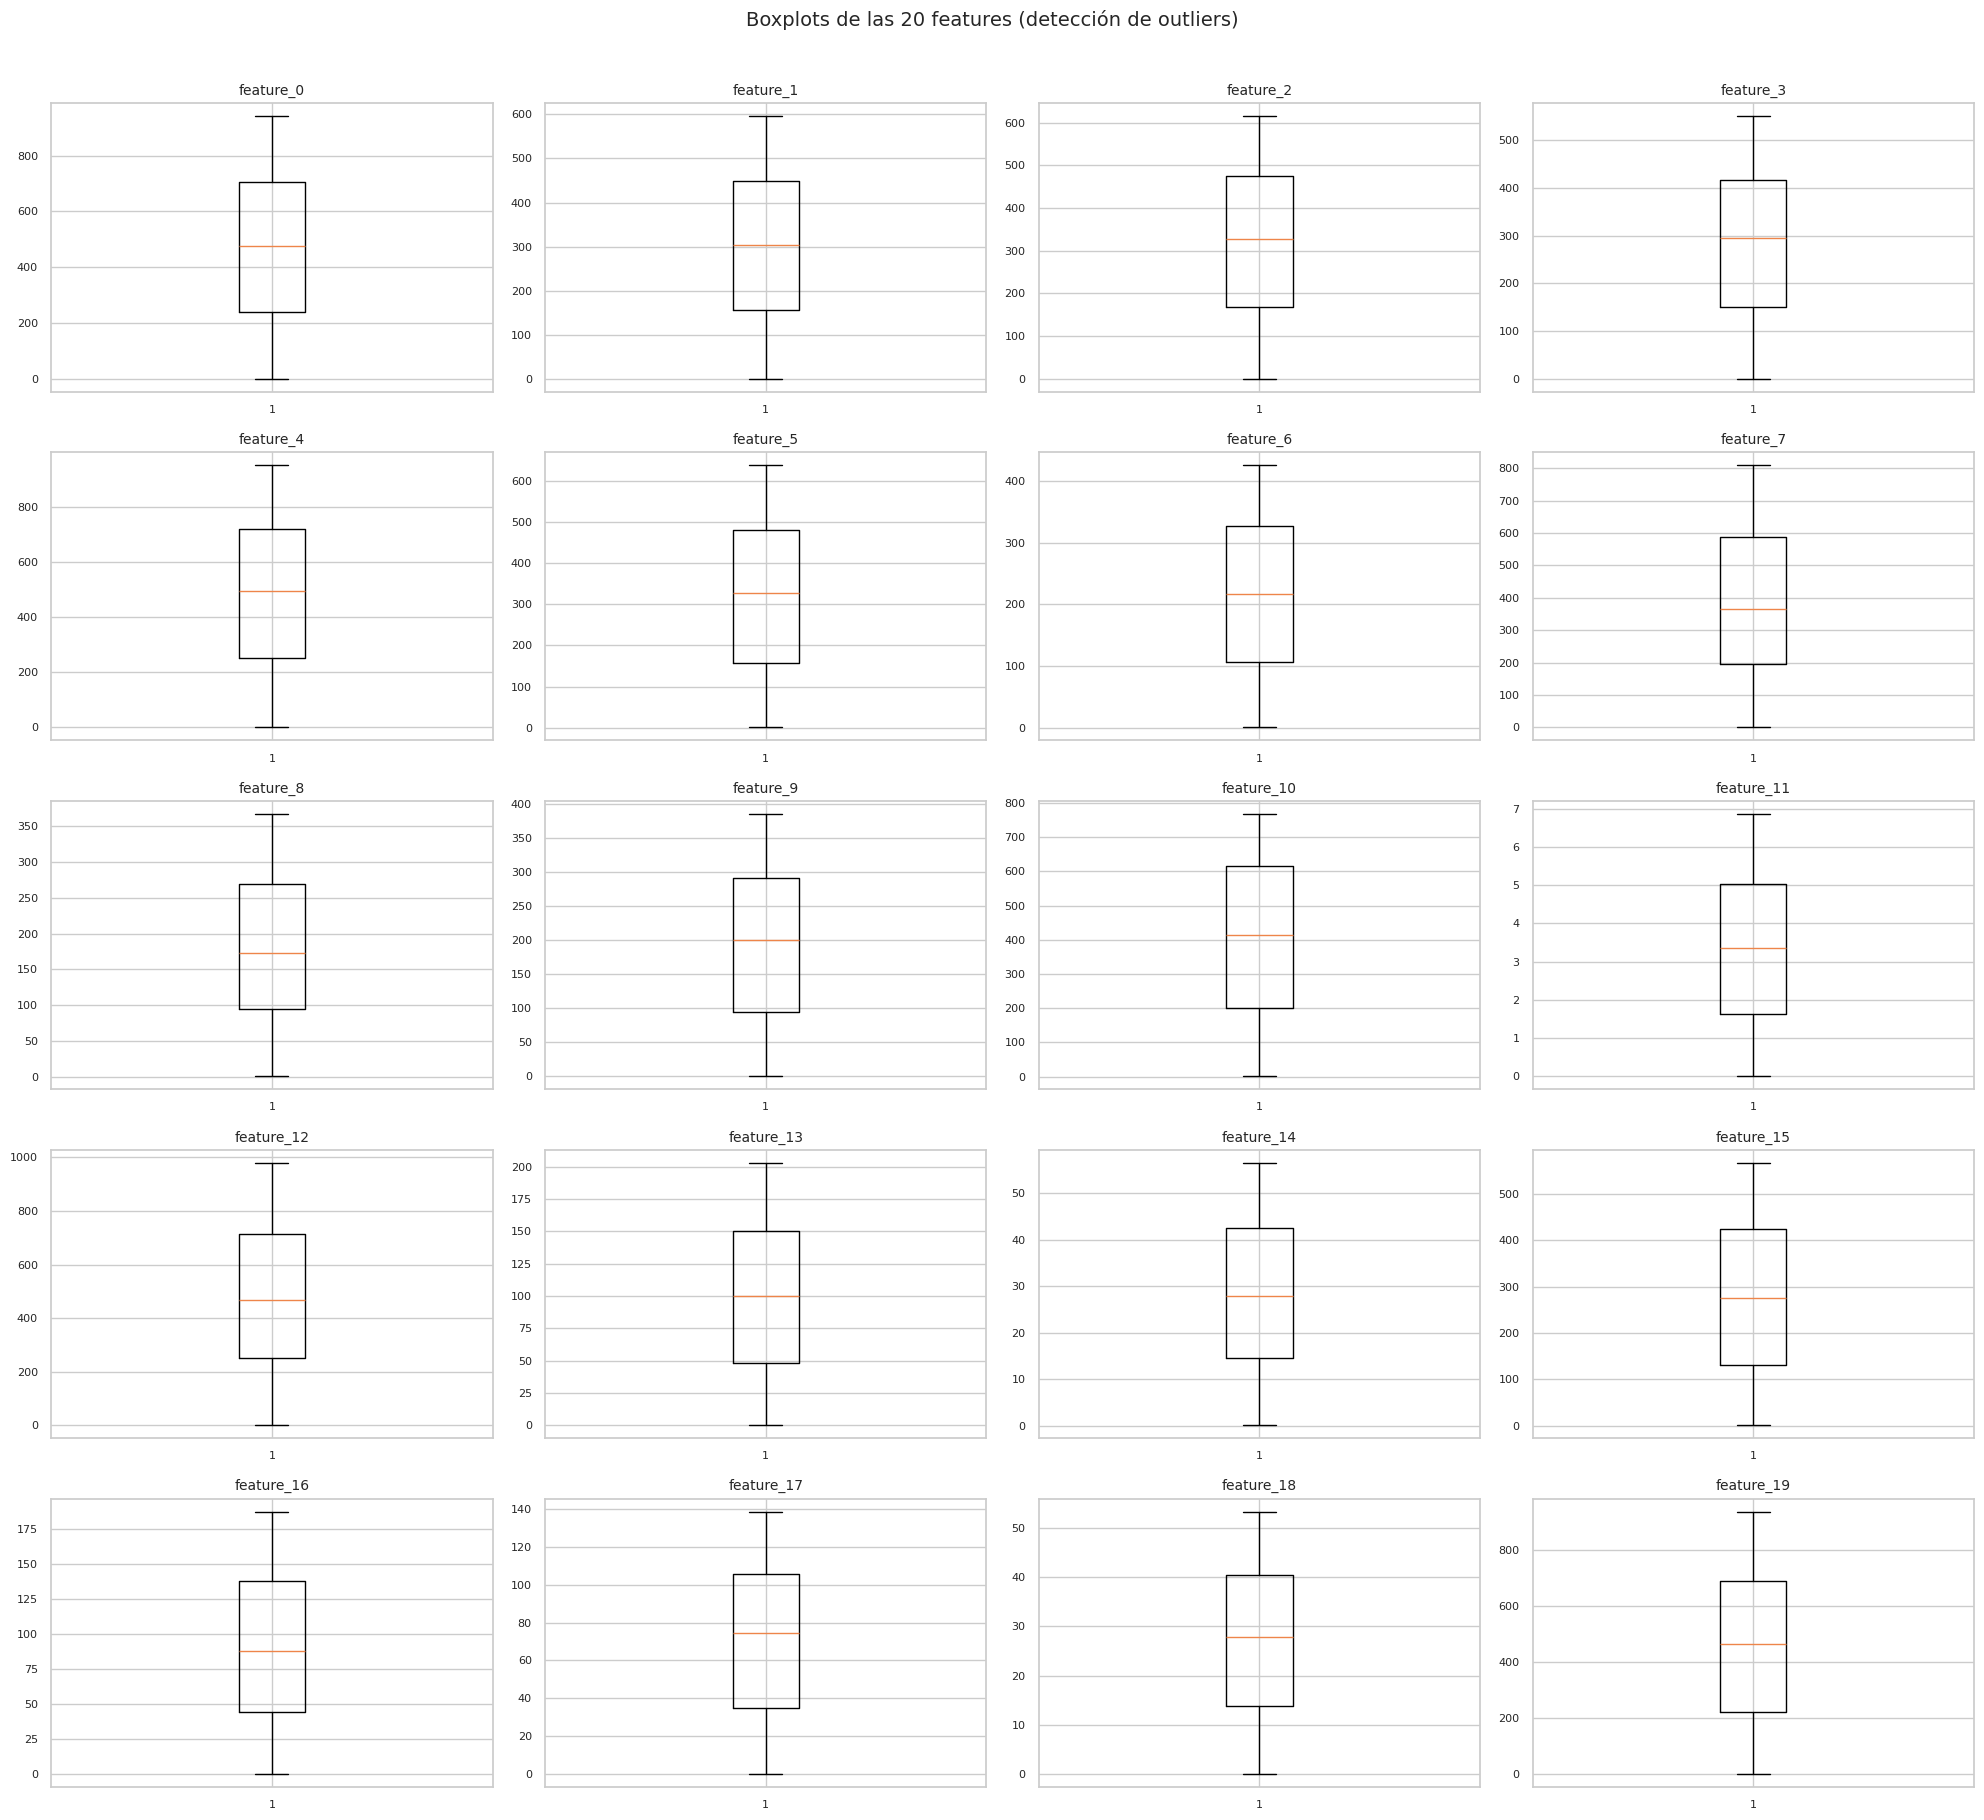

Outliers por feature (método IQR 1.5x):


In [12]:
fig, axes = plt.subplots(5, 4, figsize=(20, 18))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].boxplot(df_train[feat], vert=True)
    axes[i].set_title(feat, fontsize=10)
    axes[i].tick_params(labelsize=8)

plt.suptitle("Boxplots de las 20 features (detección de outliers)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Conteo de outliers usando IQR
print("Outliers por feature (método IQR 1.5x):")
for feat in features:
    Q1 = df_train[feat].quantile(0.25)
    Q3 = df_train[feat].quantile(0.75)
    IQR = Q3 - Q1
    n_outliers = ((df_train[feat] < Q1 - 1.5 * IQR) | (df_train[feat] > Q3 + 1.5 * IQR)).sum()
    if n_outliers > 0:
        print(f"  {feat}: {n_outliers} outliers")

## 6. Matriz de correlación

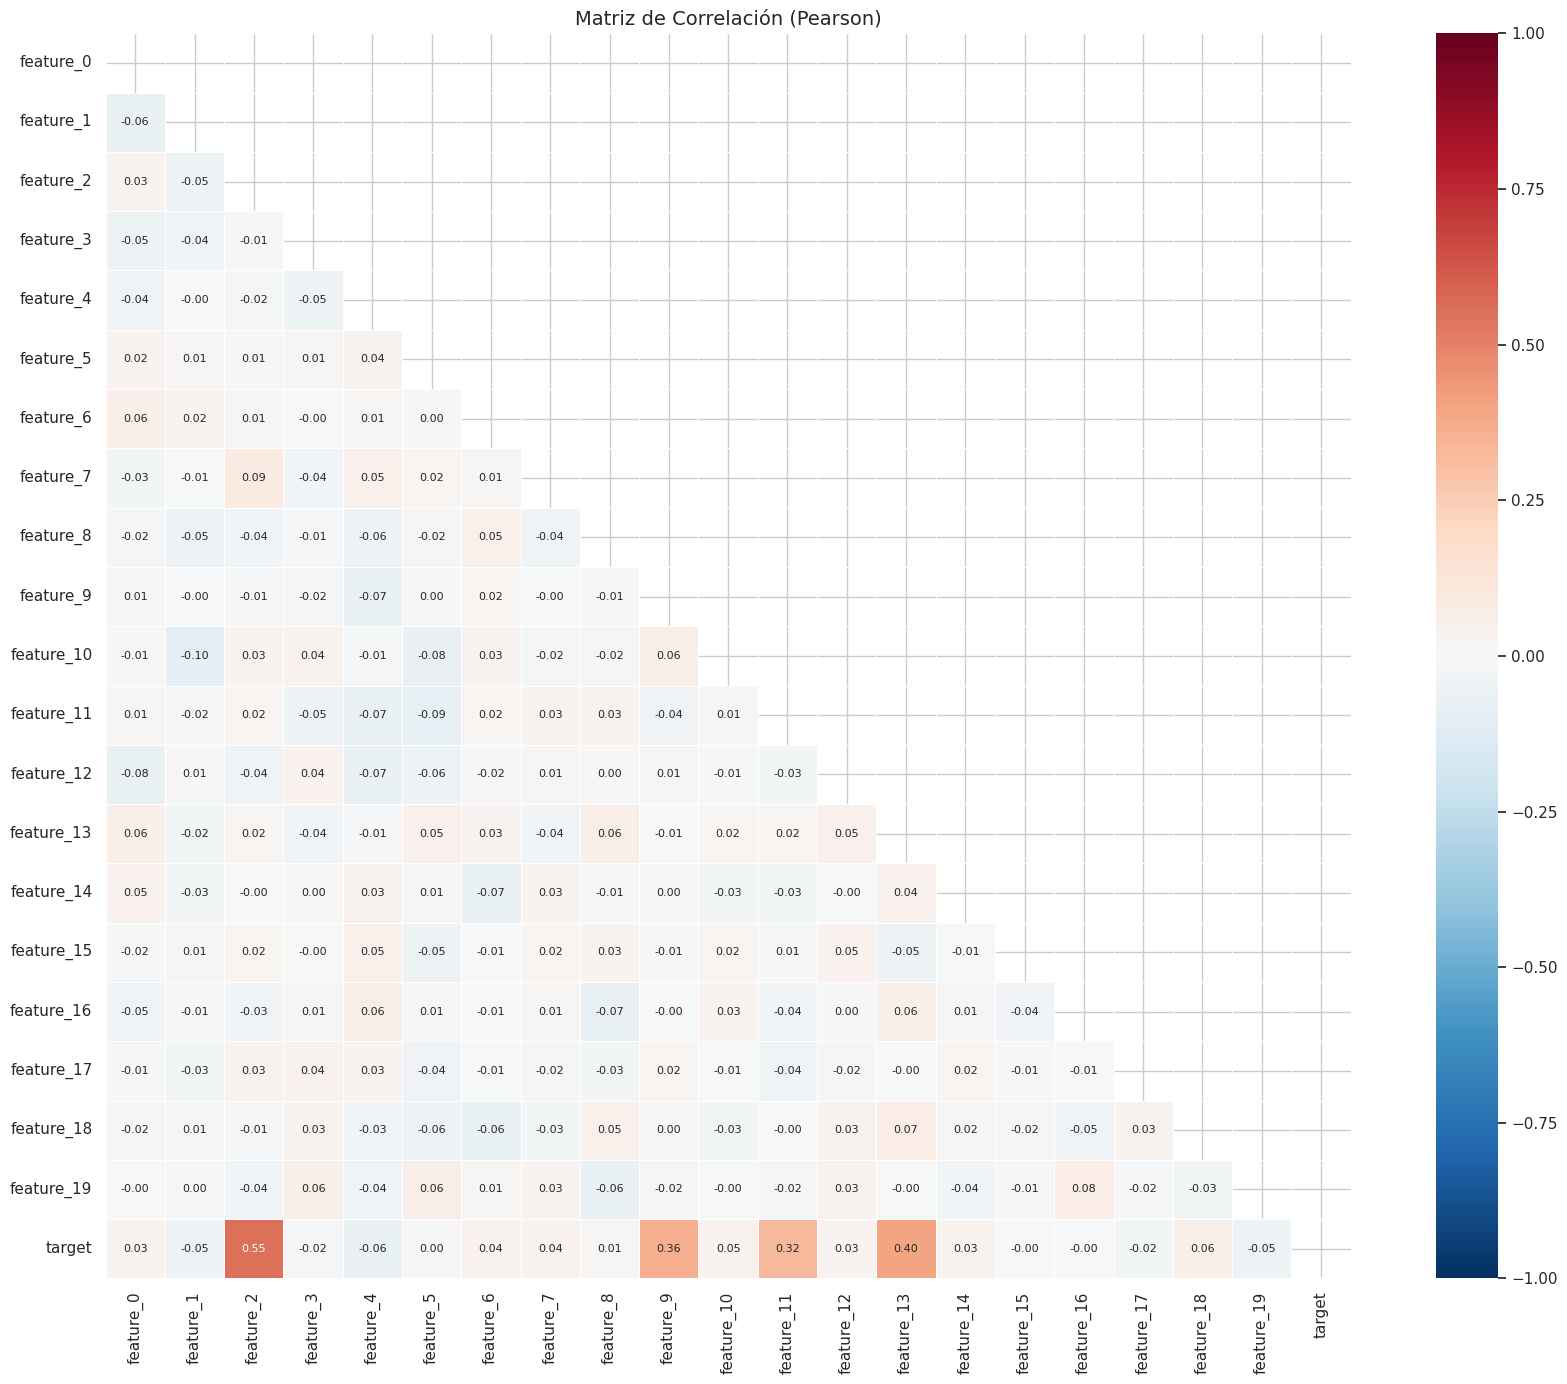

In [13]:
corr = df_train.corr()

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={"size": 8})
plt.title("Matriz de Correlación (Pearson)", fontsize=14)
plt.tight_layout()
plt.show()

Correlación con el target (ordenada por valor absoluto):

feature_2     0.5518
feature_13    0.4047
feature_9     0.3619
feature_11    0.3228
feature_4    -0.0627
feature_18    0.0601
feature_19   -0.0535
feature_1    -0.0472
feature_10    0.0455
feature_6     0.0444
feature_7     0.0411
feature_14    0.0349
feature_0     0.0341
feature_12    0.0297
feature_17   -0.0243
feature_3    -0.0168
feature_8     0.0100
feature_16   -0.0039
feature_15   -0.0006
feature_5     0.0003


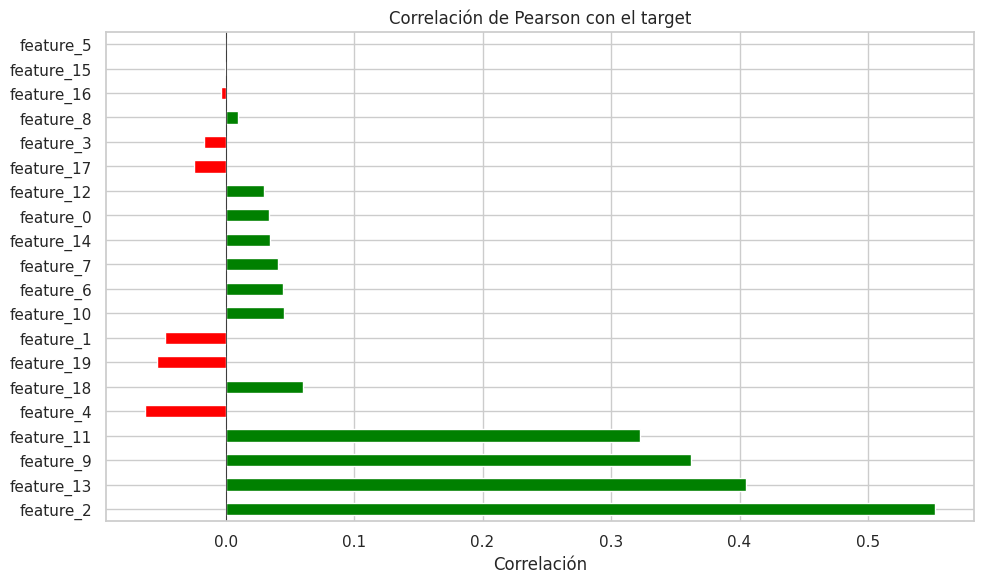

In [14]:
# Correlación de cada feature con el target, ordenadas
corr_target = corr["target"].drop("target").sort_values(key=abs, ascending=False)
print("Correlación con el target (ordenada por valor absoluto):\n")
print(corr_target.to_string())

fig, ax = plt.subplots(figsize=(10, 6))
corr_target.plot(kind="barh", ax=ax, color=["green" if x > 0 else "red" for x in corr_target])
ax.set_title("Correlación de Pearson con el target")
ax.set_xlabel("Correlación")
ax.axvline(x=0, color="black", linewidth=0.5)
plt.tight_layout()
plt.show()

In [15]:
# Pares de features con alta correlación entre sí (posible multicolinealidad)
print("Pares de features con |correlación| > 0.7:")
high_corr_pairs = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        c = corr.loc[features[i], features[j]]
        if abs(c) > 0.7:
            high_corr_pairs.append((features[i], features[j], c))
            print(f"  {features[i]} vs {features[j]}: {c:.4f}")

if not high_corr_pairs:
    print("  Ninguno encontrado.")

Pares de features con |correlación| > 0.7:
  Ninguno encontrado.


## 7. Scatter plots: features vs target

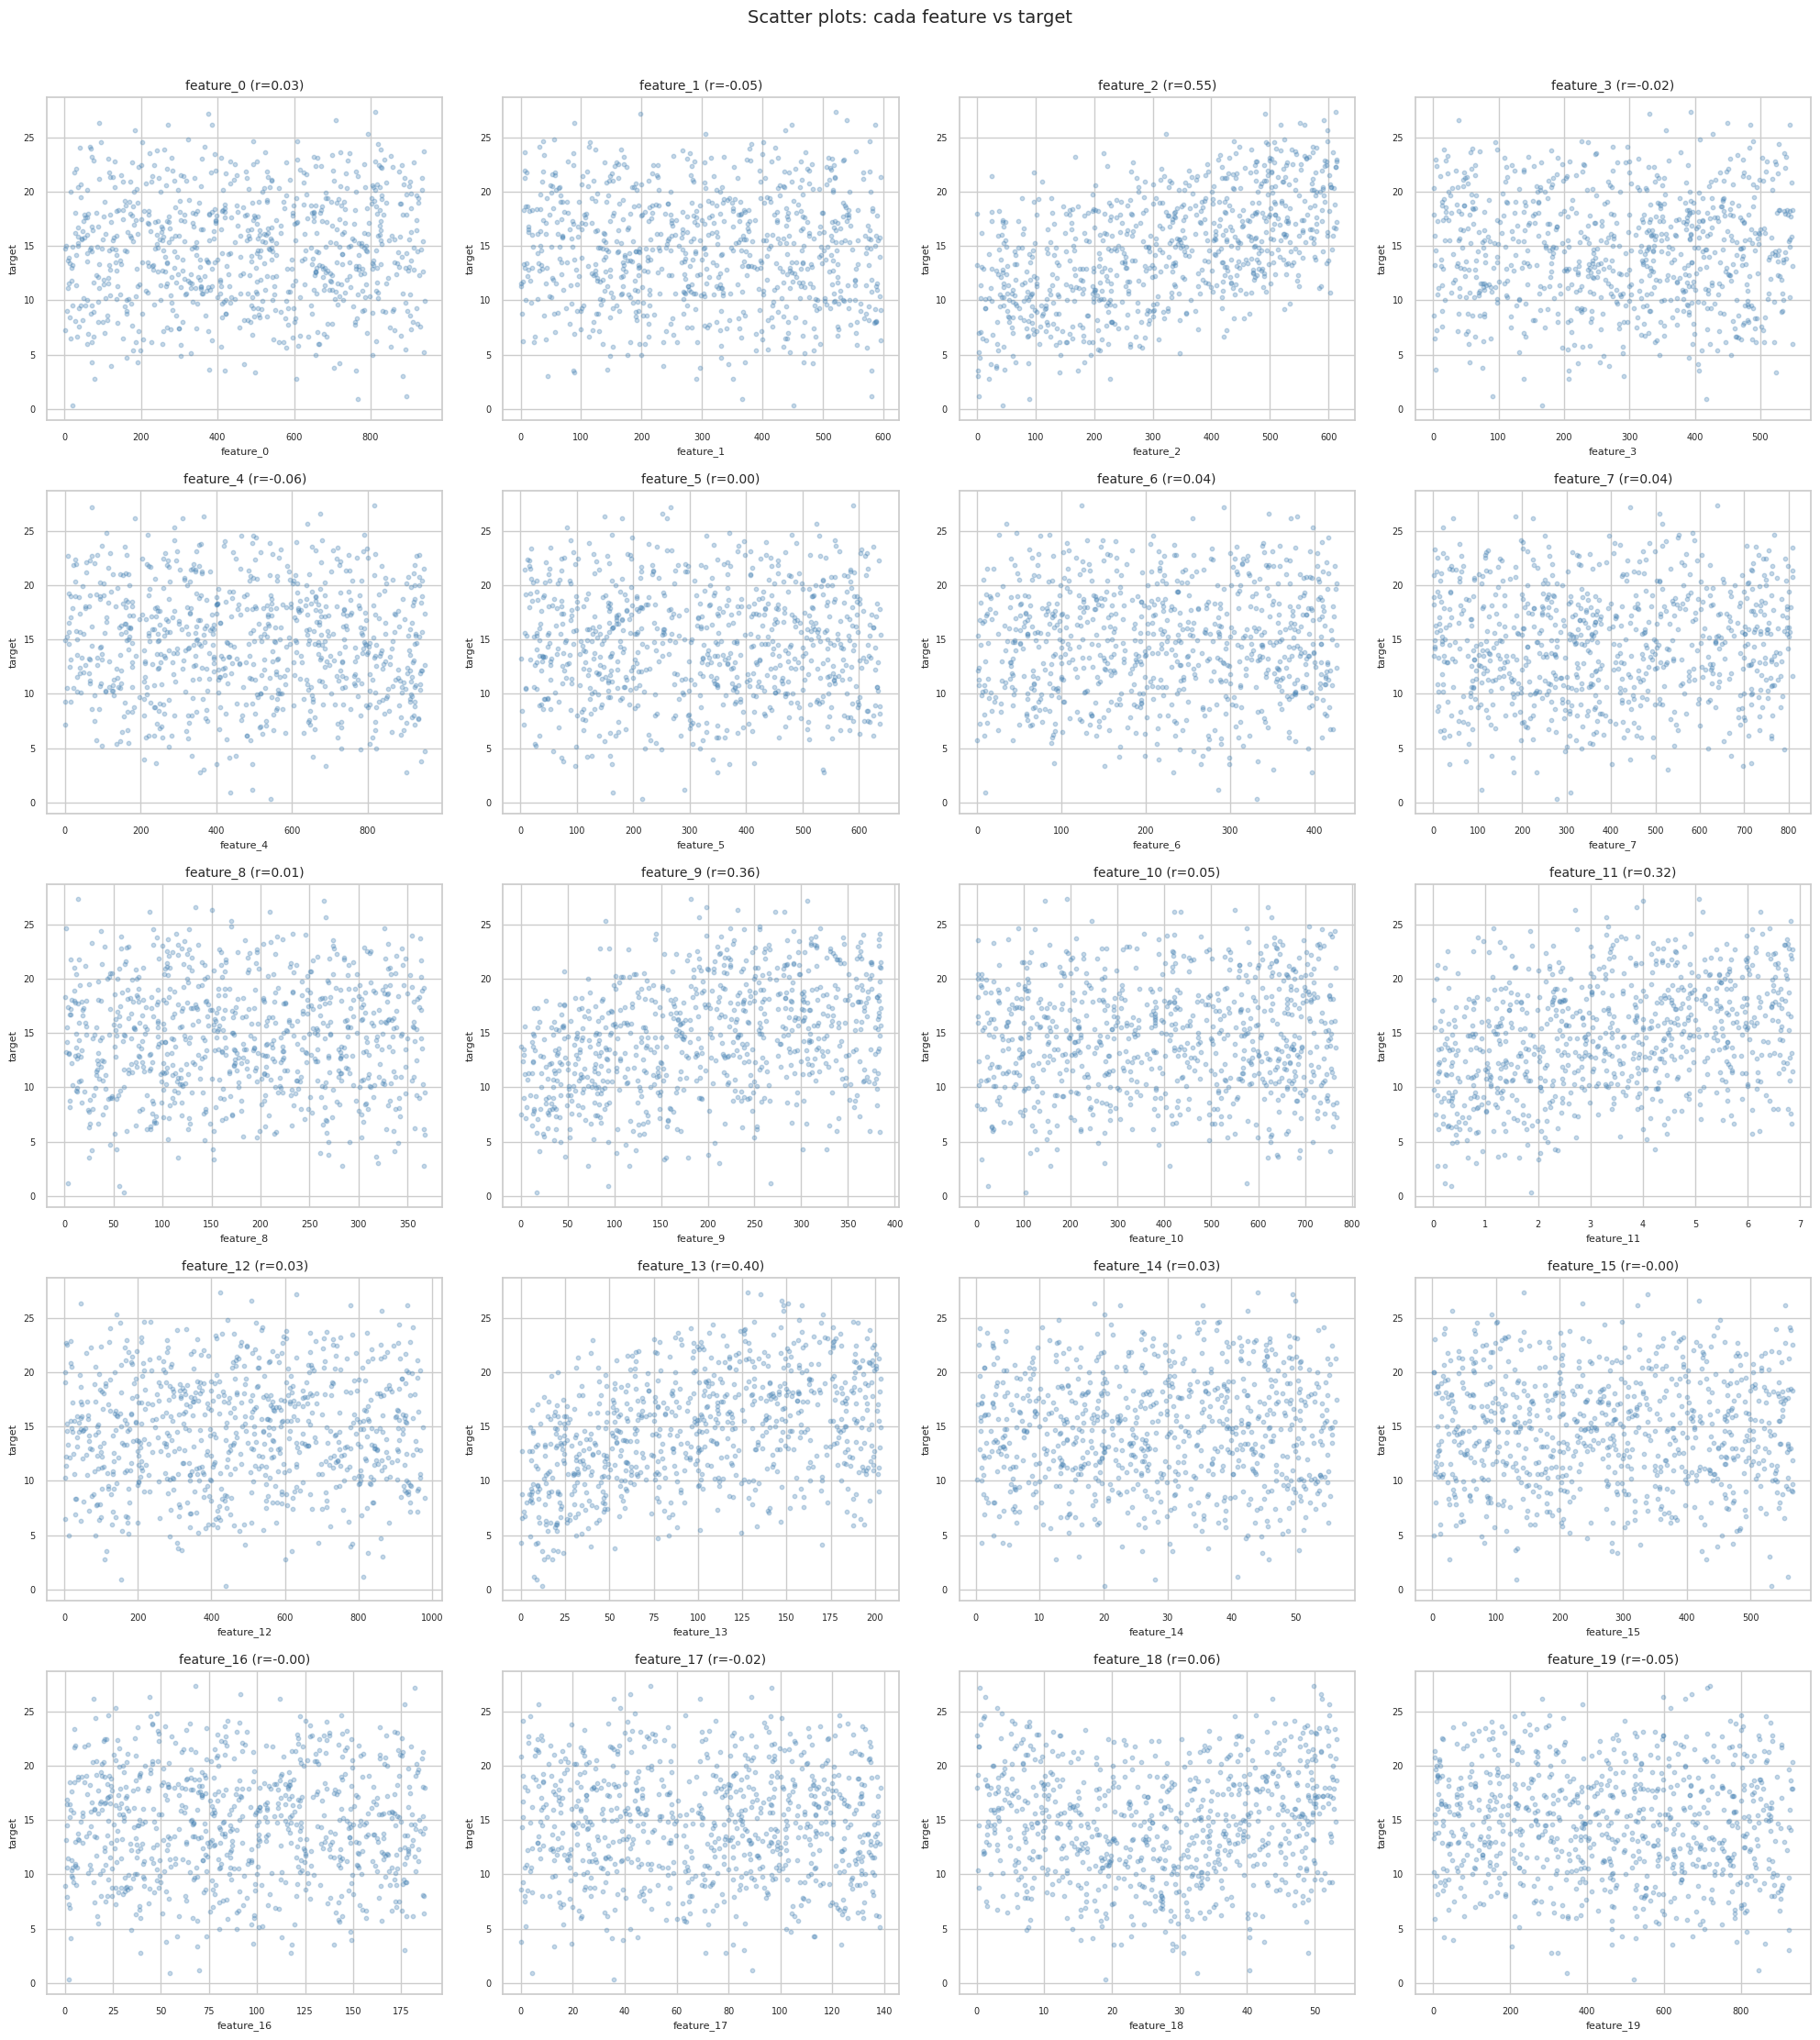

In [16]:
fig, axes = plt.subplots(5, 4, figsize=(20, 22))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].scatter(df_train[feat], df_train["target"], alpha=0.3, s=10, color="steelblue")
    axes[i].set_title(f"{feat} (r={corr.loc[feat, 'target']:.2f})", fontsize=10)
    axes[i].set_xlabel(feat, fontsize=8)
    axes[i].set_ylabel("target", fontsize=8)
    axes[i].tick_params(labelsize=7)

plt.suptitle("Scatter plots: cada feature vs target", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 8. Comparación de distribuciones: Train vs Test

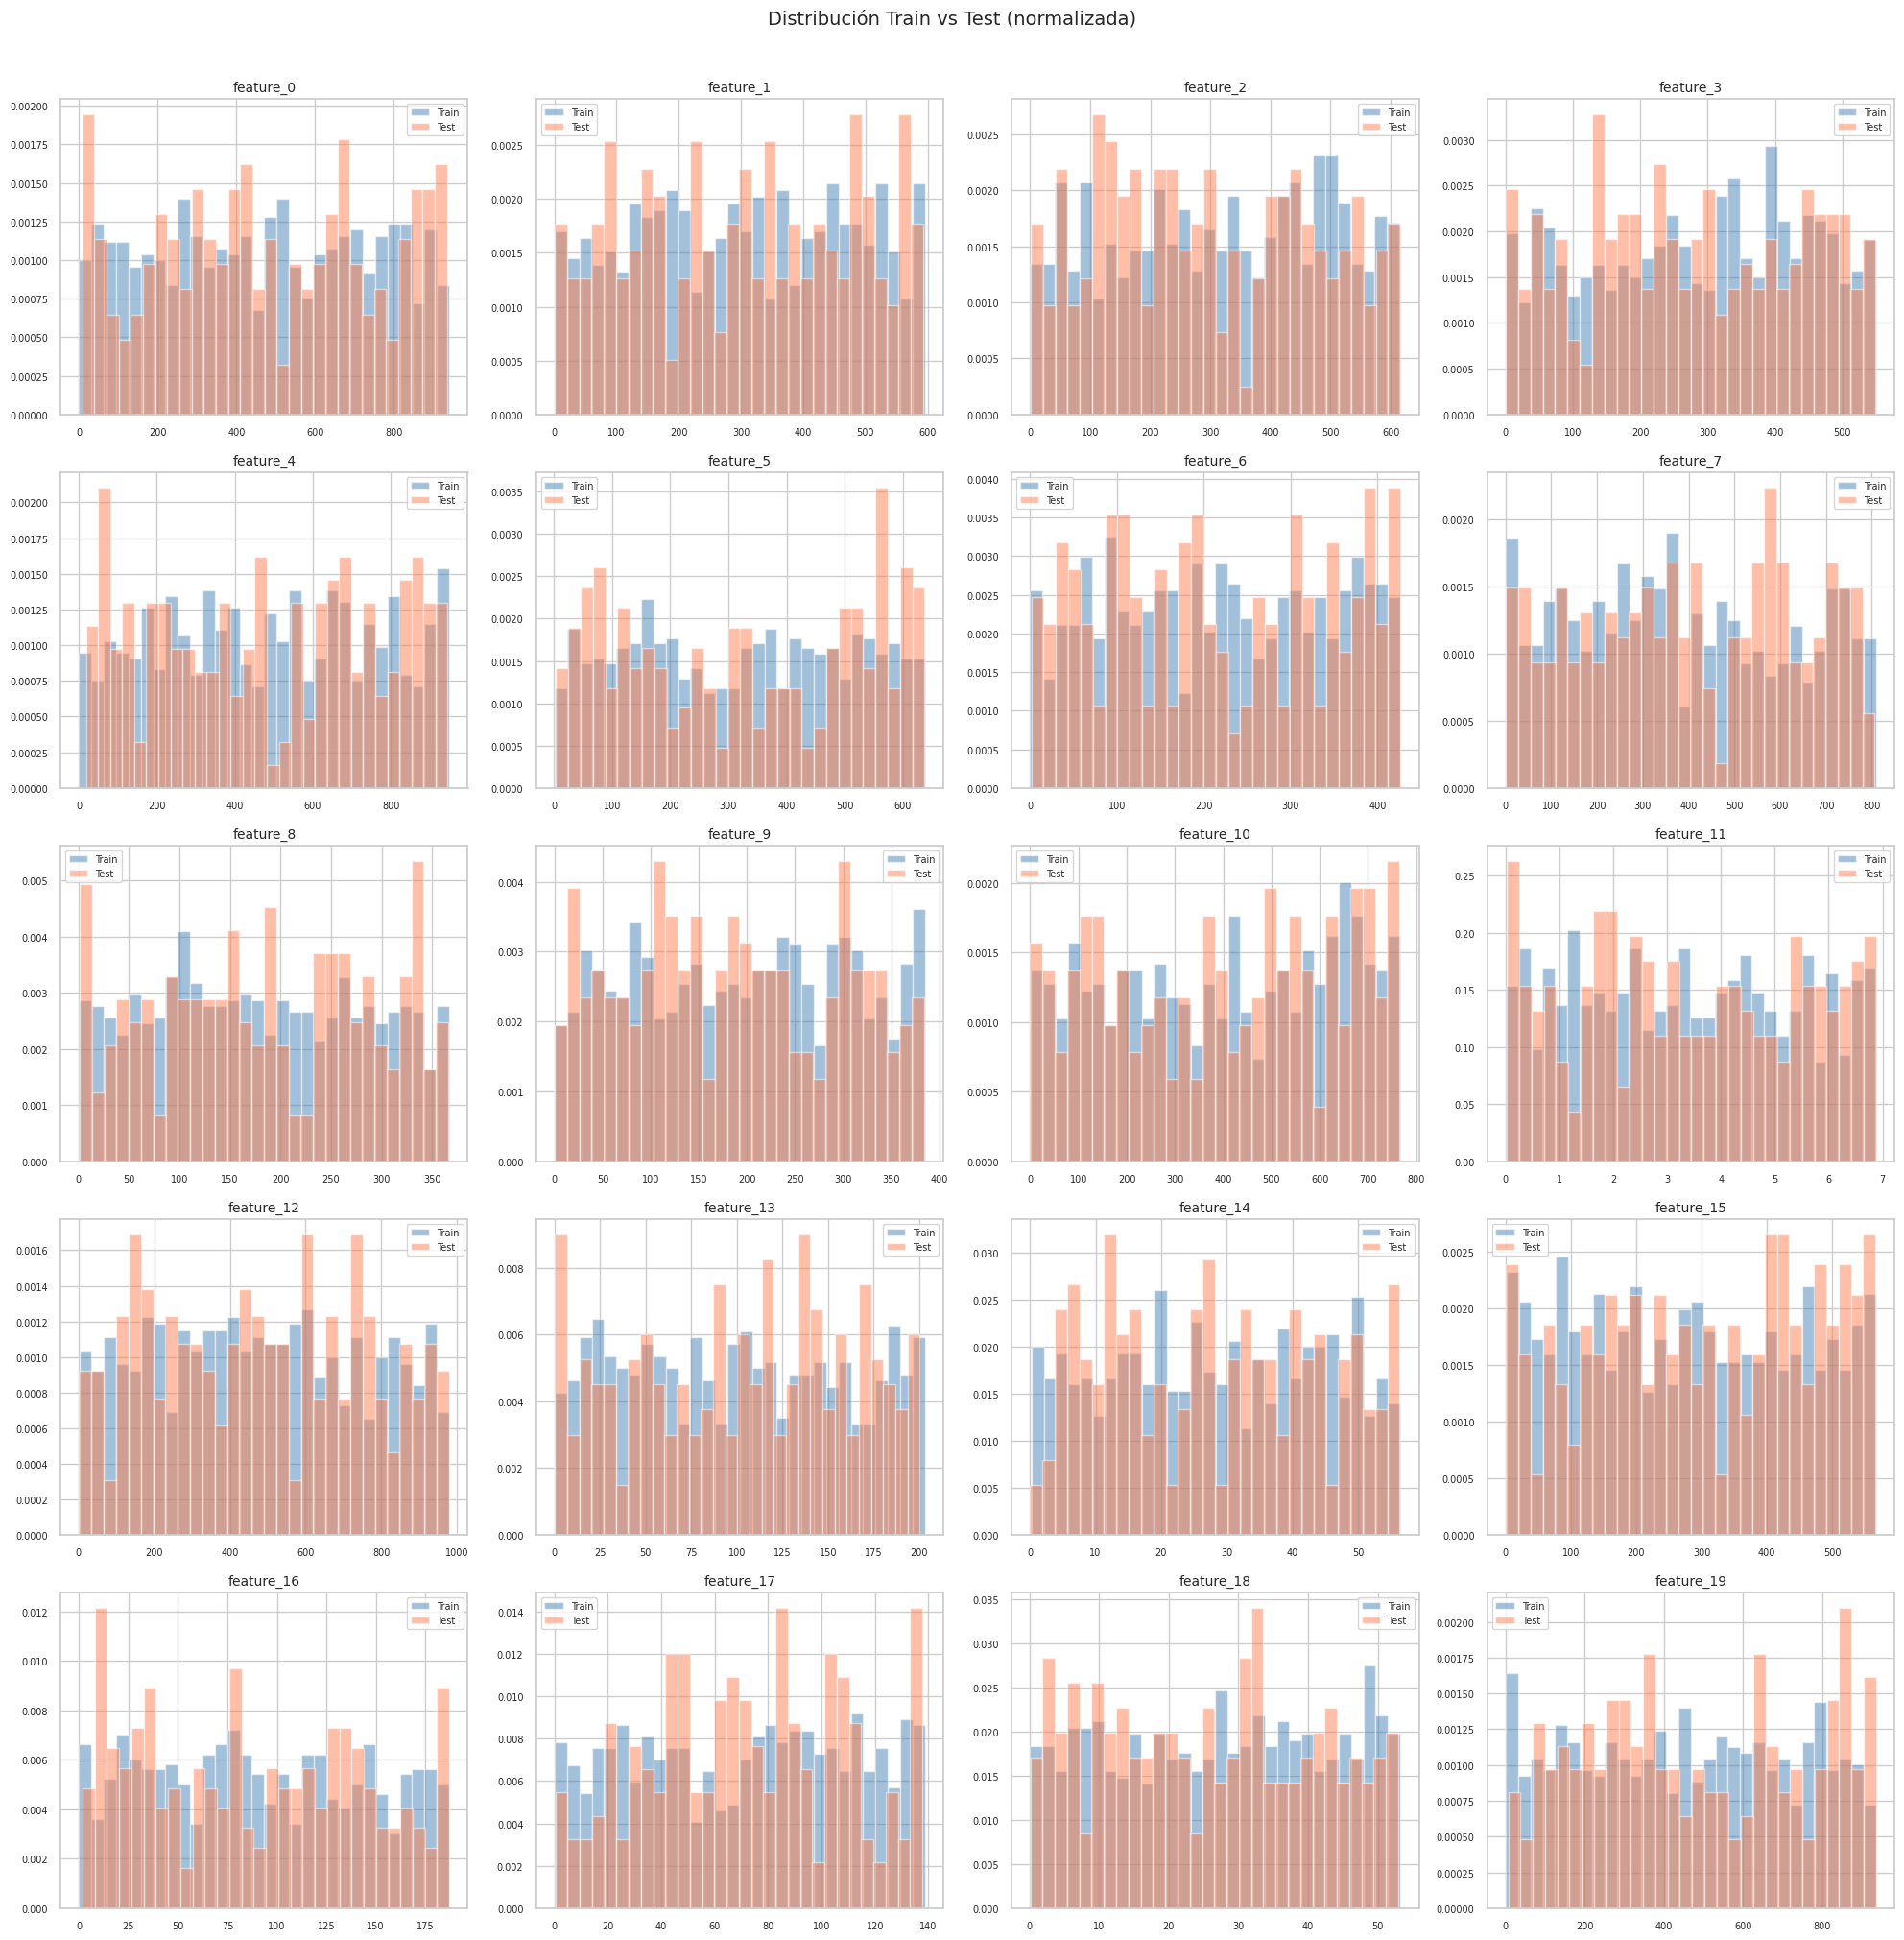

In [17]:
fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()

for i, feat in enumerate(features):
    axes[i].hist(df_train[feat], bins=30, alpha=0.5, label="Train", color="steelblue", density=True)
    axes[i].hist(df_test[feat], bins=30, alpha=0.5, label="Test", color="coral", density=True)
    axes[i].set_title(feat, fontsize=10)
    axes[i].legend(fontsize=7)
    axes[i].tick_params(labelsize=7)

plt.suptitle("Distribución Train vs Test (normalizada)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [18]:
# Test KS para verificar si train y test vienen de la misma distribución
print("Kolmogorov-Smirnov test (Train vs Test):\n")
for feat in features:
    stat, p = stats.ks_2samp(df_train[feat], df_test[feat])
    flag = " *** DRIFT" if p < 0.05 else ""
    print(f"  {feat:>12s}: KS={stat:.4f}, p={p:.4f}{flag}")

Kolmogorov-Smirnov test (Train vs Test):

     feature_0: KS=0.0650, p=0.4966
     feature_1: KS=0.0288, p=0.9992
     feature_2: KS=0.0850, p=0.1914
     feature_3: KS=0.0638, p=0.5217
     feature_4: KS=0.0525, p=0.7581
     feature_5: KS=0.1013, p=0.0721
     feature_6: KS=0.0488, p=0.8310
     feature_7: KS=0.0912, p=0.1342
     feature_8: KS=0.0587, p=0.6262
     feature_9: KS=0.0775, p=0.2831
    feature_10: KS=0.0350, p=0.9875
    feature_11: KS=0.0488, p=0.8310
    feature_12: KS=0.0387, p=0.9656
    feature_13: KS=0.0663, p=0.4721
    feature_14: KS=0.0525, p=0.7581
    feature_15: KS=0.0862, p=0.1787
    feature_16: KS=0.0638, p=0.5217
    feature_17: KS=0.0850, p=0.1914
    feature_18: KS=0.0725, p=0.3596
    feature_19: KS=0.0788, p=0.2659


## 9. Análisis de relaciones no lineales (Spearman + Información mutua)

Comparación de métricas de asociación con el target:

            Pearson  Spearman  Mutual_Info
feature_2    0.5518    0.5434       0.1839
feature_13   0.4047    0.4024       0.1285
feature_16  -0.0039   -0.0083       0.0628
feature_9    0.3619    0.3677       0.0532
feature_3   -0.0168   -0.0189       0.0367
feature_18   0.0601    0.0706       0.0295
feature_11   0.3228    0.3175       0.0266
feature_5    0.0003   -0.0055       0.0247
feature_1   -0.0472   -0.0494       0.0198
feature_12   0.0297    0.0269       0.0157
feature_15  -0.0006    0.0032       0.0137
feature_4   -0.0627   -0.0626       0.0123
feature_17  -0.0243   -0.0255       0.0099
feature_0    0.0341    0.0382       0.0000
feature_6    0.0444    0.0454       0.0000
feature_7    0.0411    0.0391       0.0000
feature_10   0.0455    0.0381       0.0000
feature_8    0.0100    0.0150       0.0000
feature_14   0.0349    0.0328       0.0000
feature_19  -0.0535   -0.0566       0.0000


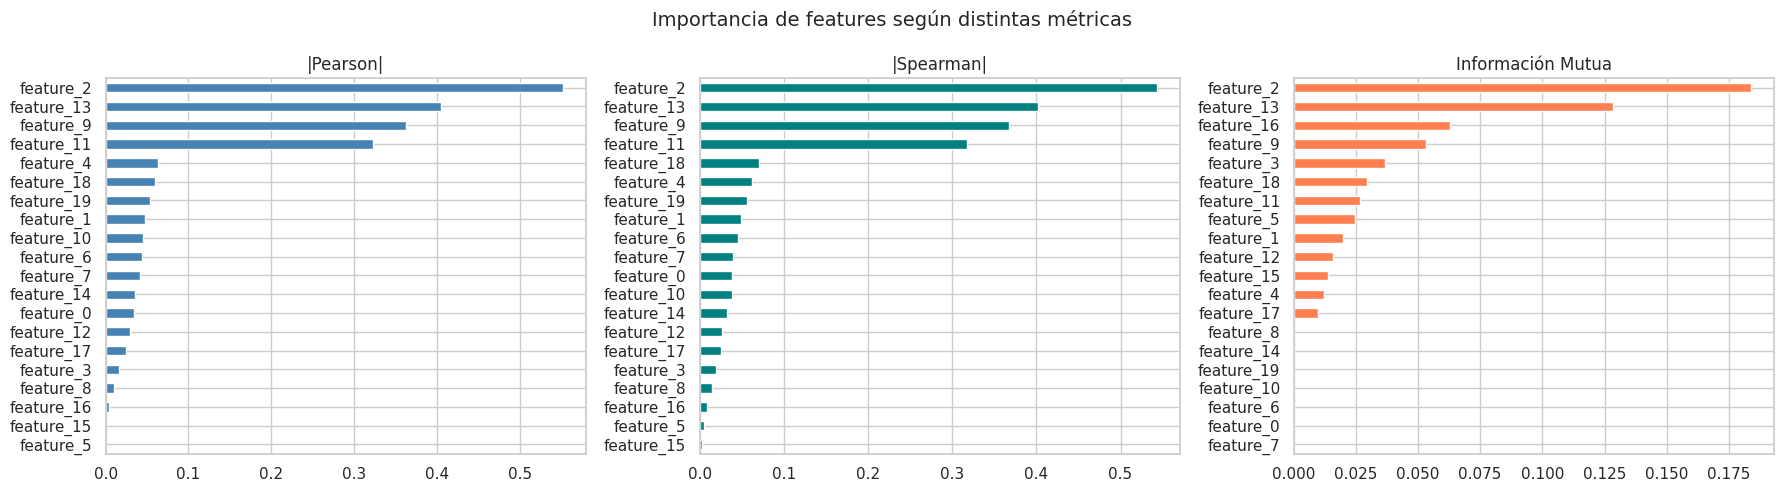

In [19]:
from sklearn.feature_selection import mutual_info_regression

# Spearman (captura relaciones monótonas no lineales)
spearman_corr = df_train[features + ["target"]].corr(method="spearman")["target"].drop("target")

# Información mutua (captura dependencias no lineales generales)
mi = mutual_info_regression(df_train[features], df_train["target"], random_state=42)
mi_series = pd.Series(mi, index=features)

comparison = pd.DataFrame({
    "Pearson": corr["target"].drop("target"),
    "Spearman": spearman_corr,
    "Mutual_Info": mi_series
}).sort_values("Mutual_Info", ascending=False)

print("Comparación de métricas de asociación con el target:\n")
print(comparison.to_string())

# Visualizar
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

comparison["Pearson"].abs().sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("|Pearson|")

comparison["Spearman"].abs().sort_values().plot(kind="barh", ax=axes[1], color="teal")
axes[1].set_title("|Spearman|")

comparison["Mutual_Info"].sort_values().plot(kind="barh", ax=axes[2], color="coral")
axes[2].set_title("Información Mutua")

plt.suptitle("Importancia de features según distintas métricas", fontsize=14)
plt.tight_layout()
plt.show()

## 10. PCA - Análisis de componentes principales

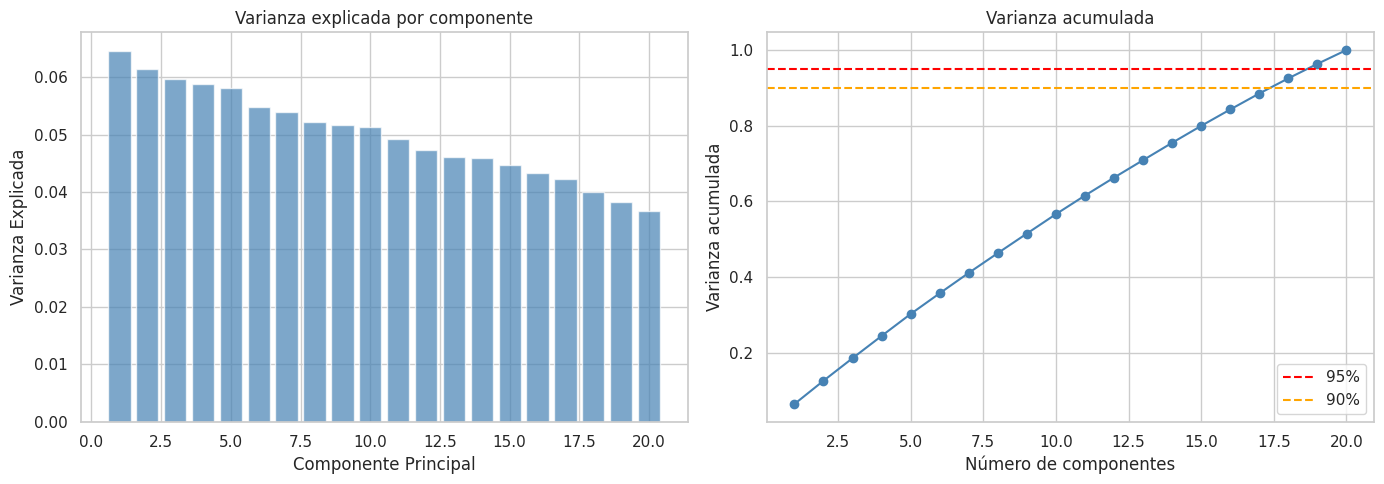

Componentes para 90% varianza: 18
Componentes para 95% varianza: 19


In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_train[features])

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Varianza explicada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, 21), pca.explained_variance_ratio_, alpha=0.7, color="steelblue")
axes[0].set_xlabel("Componente Principal")
axes[0].set_ylabel("Varianza Explicada")
axes[0].set_title("Varianza explicada por componente")

cum_var = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(range(1, 21), cum_var, "o-", color="steelblue")
axes[1].axhline(y=0.95, color="red", linestyle="--", label="95%")
axes[1].axhline(y=0.90, color="orange", linestyle="--", label="90%")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada")
axes[1].set_title("Varianza acumulada")
axes[1].legend()

plt.tight_layout()
plt.show()

n_95 = np.argmax(cum_var >= 0.95) + 1
n_90 = np.argmax(cum_var >= 0.90) + 1
print(f"Componentes para 90% varianza: {n_90}")
print(f"Componentes para 95% varianza: {n_95}")

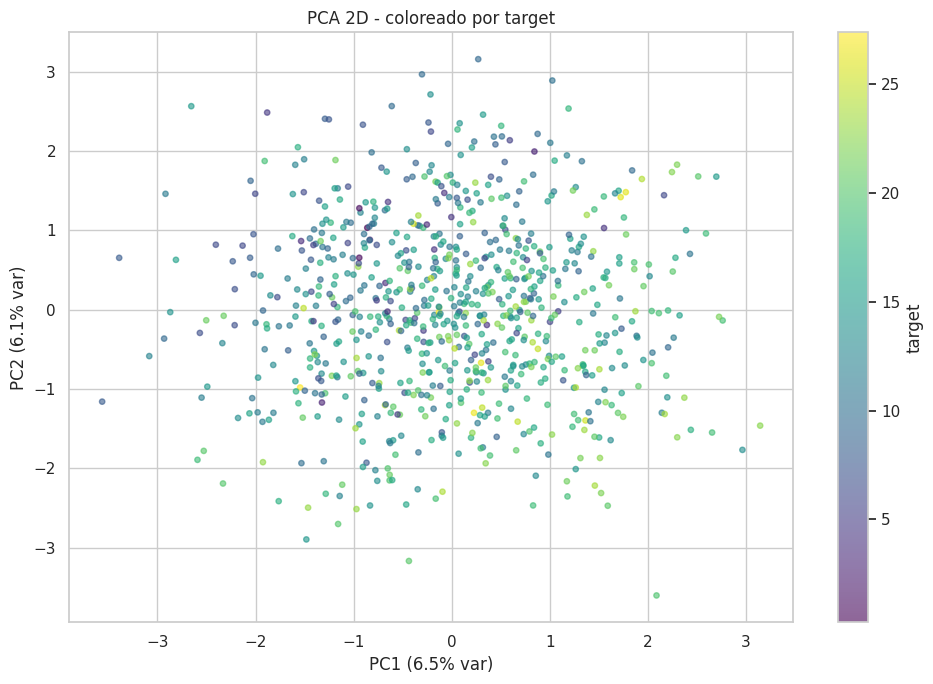

In [21]:
# PCA 2D coloreado por target
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=df_train["target"], cmap="viridis", alpha=0.6, s=15)
plt.colorbar(scatter, label="target")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
ax.set_title("PCA 2D - coloreado por target")
plt.tight_layout()
plt.show()

## 11. Baseline rápido con regresión lineal (validación cruzada)

In [22]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score

X = df_train[features].values
y = df_train["target"].values

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1.0),
    "Lasso (alpha=1)": Lasso(alpha=1.0),
}

print("Baseline - Cross-Validation (5-fold):\n")
print(f"{'Modelo':<25s} {'R² (mean ± std)':>20s}  {'MAE (mean ± std)':>20s}")
print("-" * 70)

for name, model in models.items():
    r2_scores = cross_val_score(model, X, y, cv=5, scoring="r2")
    mae_scores = -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error")
    print(f"{name:<25s} {r2_scores.mean():>8.4f} ± {r2_scores.std():.4f}  {mae_scores.mean():>8.4f} ± {mae_scores.std():.4f}")

Baseline - Cross-Validation (5-fold):

Modelo                         R² (mean ± std)      MAE (mean ± std)
----------------------------------------------------------------------
Linear Regression           0.6759 ± 0.0402    2.2197 ± 0.0722
Ridge (alpha=1)             0.6759 ± 0.0402    2.2197 ± 0.0722
Lasso (alpha=1)             0.6656 ± 0.0424    2.2541 ± 0.1149


## 12. Resumen y hallazgos clave

### Hallazgos del EDA

**Dataset:**
- Training: 800 muestras, 20 features + 1 target continuo
- Blind test: 200 muestras, 20 features (sin target)
- Sin valores nulos ni duplicados

**Target:**
- Revisar distribución, asimetría y si se aproxima a normalidad (QQ-plot y Shapiro-Wilk)

**Features:**
- Revisar rangos y escalas variadas entre features
- Identificar features con distribuciones sesgadas (alta asimetría)
- Evaluar presencia de outliers según método IQR

**Correlaciones y relevancia:**
- Identificar features con mayor correlación lineal (Pearson) y no lineal (Spearman, MI) con el target
- Detectar posibles problemas de multicolinealidad entre features

**Train vs Test:**
- Verificar con test KS si hay data drift entre train y test

**PCA:**
- Determinar cuántas componentes capturan el 90-95% de la varianza
- Visualizar estructura en 2D coloreado por target

**Baseline:**
- Resultados de regresión lineal, Ridge y Lasso como punto de partida

### Próximos pasos sugeridos
1. Feature engineering basado en las relaciones descubiertas
2. Probar modelos no lineales (Random Forest, XGBoost, etc.)
3. Optimización de hiperparámetros
4. Evaluar si la reducción de dimensionalidad (PCA) mejora el rendimiento